# Module 8 — Efficient Fine-Tuning and Data Engineering

## Lesson 8.1 — Understanding Model Adaptation


Module 7 ended with a decision. For flagging negative movie reviews, the best model we could *download* was a sentiment model fine-tuned on short sentences from another dataset. A model fine-tuned on IMDb itself looked better, but it came with no licence and had already seen our validation data. The obvious next thought is: why not adapt a model to our data ourselves?

That is what Module 8 is about. **Adaptation** means taking a general-purpose pretrained model and making it better at one specific task. There is more than one way to do it, from simply asking a model in plain words, through training a small classifier on its features, to updating all of its weights. Each way costs different amounts of data and computing, and each changes the model in different ways, some of them unwanted.

This first note gives the whole picture before the later notes take it apart: 8.2 prepares the data, 8.3 sets the baselines any adapted model must beat, 8.4 fine-tunes a model fully, 8.5 does it efficiently with LoRA, 8.6 looks at how large language models are adapted, and 8.7 evaluates the results and decides what to keep.

**Key question:** *How can we adapt pretrained models to specific tasks without updating every parameter, and how do we prepare data for reliable adaptation?*

### Learning objectives
- describe the adaptation spectrum (prompting, feature extraction, parameter-efficient fine-tuning, full fine-tuning) and what each changes;
- try prompting and feature extraction on the same reviews and compare them;
- explain when fine-tuning is worth it, and when it isn't;
- describe what changes inside a model during full fine-tuning, with measurements;
- recognise overfitting and catastrophic forgetting, and measure both;
- weigh data, compute and quality when choosing a strategy.

### Prerequisites

 this note builds on Module 7, especially pretrained bodies and heads (7.1), the fixed IMDb split (7.1), and the model-selection process (7.7). You will also use training loops and overfitting from Modules 2 and 3, and the decoding and chat ideas from Notes 6.6 and 7.5.

### Setup

The usual imports, seeds and device check. This note downloads one new model, SmolLM2-360M-Instruct (several hundred megabytes), so the first run takes a while. The usual harmless warnings appear: the TqdmWarning, the unauthenticated-request message, the "Loading weights" bars and, on a Mac, a few `W…` lines. One LOAD REPORT appears in Section 4, when DistilBERT gets a new classification head; Note 7.1 explained these.

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

In [1]:
import time, copy, hashlib
import numpy as np
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from transformers import (AutoTokenizer, AutoModel, AutoModelForCausalLM,
                          AutoModelForSequenceClassification, AutoModelForMaskedLM)

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1 | device: cpu


## 1. The Big Picture: From General-Purpose to Task-Specific

A pretrained model is a generalist. DistilBERT knows English well, from guessing hidden words in books and Wikipedia (Note 7.1). A small chat model knows how to follow instructions. Neither knows what *our* product team means by a negative review, which reviews matter, or how our users write. Adaptation closes that gap, and the main ways to do it form a spectrum, ordered by how much of the model they change:

| Approach | What changes | Labelled data needed | Compute needed |
|---|---|---|---|
| **Prompting** | nothing: we only change the input, by describing the task in words | none (or a few examples in the prompt) | inference only |
| **Feature extraction** | a small new model trained on the frozen model's outputs | some | one pass over the data, plus a quick fit |
| **Parameter-efficient fine-tuning (PEFT)** | a small set of new or selected weights inside the model | some to many | training, but with few weights to update |
| **Full fine-tuning** | every weight in the model | many | training of the whole model |

Moving down the table, adaptation becomes more powerful, but also costs more data and compute, and risks damaging what the model already knew. The rest of this note tries each approach on the same task and data, so the trade-offs are measured, not just described.

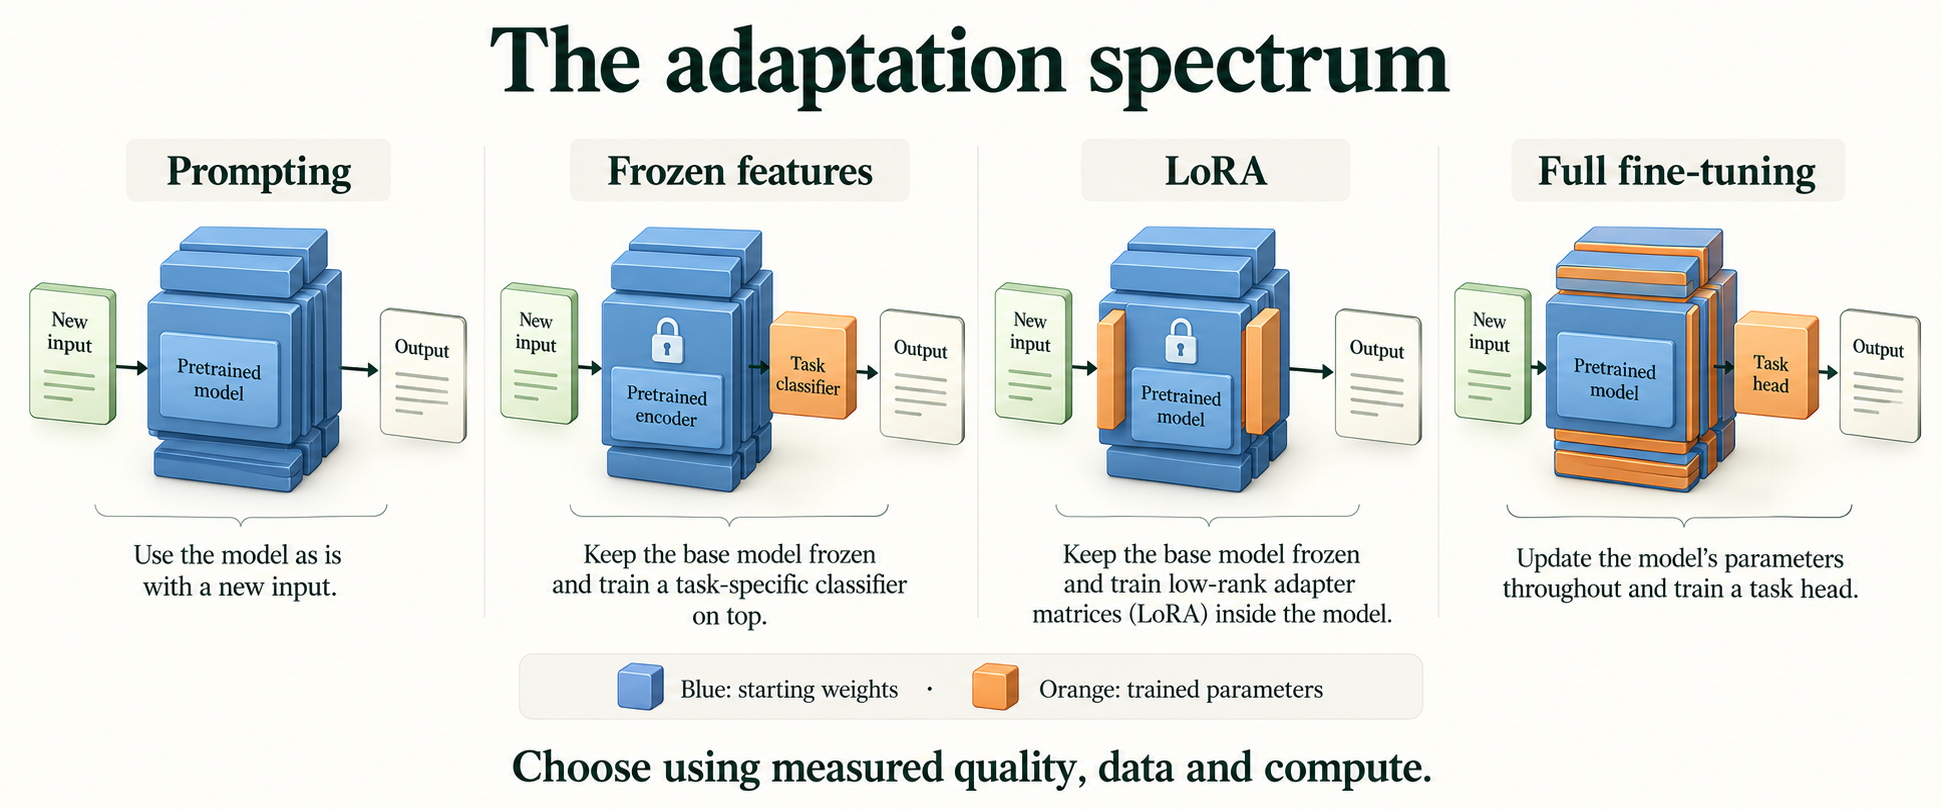

*Figure 8.1.1. Prompting changes the input; a frozen encoder supports a trained head; LoRA changes selected adapters; full fine-tuning makes the selected base parameters trainable. More complexity need not improve quality.*

### The data

Everything in Module 8 uses the fixed IMDb split from Note 7.1. The function is copied here, and the fingerprints confirm the same reviews.

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


Many reviews are longer than the 128 tokens we'll feed DistilBERT in this module. Rather than keeping only the start of each review, the helper below keeps the beginning *and the end*, where reviewers often give their verdict. Note 8.2 explains this choice and measures how much it helps.

In [4]:
BASE = "distilbert/distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE))

def head_tail(texts, max_length=128):
    """Keep the first quarter and last three quarters of the token budget (explained in Note 8.2)."""
    keep = max_length - 2                                         # room for [CLS] and [SEP]
    head = keep // 4
    rows = []
    for ids in tok(texts, add_special_tokens=False)["input_ids"]:
        if len(ids) > keep:
            ids = ids[:head] + ids[-(keep - head):]               # beginning + end of the review
        rows.append([tok.cls_token_id] + ids + [tok.sep_token_id])
    n = max(len(r) for r in rows)
    input_ids = torch.tensor([r + [tok.pad_token_id] * (n - len(r)) for r in rows])   # (B, n)
    return {"input_ids": input_ids, "attention_mask": (input_ids != tok.pad_token_id).long()}

## 2. The Adaptation Spectrum: Prompting, Feature Extraction, PEFT, Full Fine-Tuning

We'll compare the approaches on the first 100 validation reviews, where every review is worth one percentage point of accuracy.

### 2.1 Prompting: describe the task in words

The cheapest adaptation changes no weights at all. With an instruction-following model, you write the task as a question, and the model answers. We use SmolLM2-360M-Instruct, a small open chat model with about 360 million parameters, loaded in float32 because its stored bfloat16 format is very slow on most CPUs (Note 7.6). Its **chat template** (Note 8.6 looks inside) wraps our question in the special markers the model was trained with:

In [5]:
LLM = "HuggingFaceTB/SmolLM2-360M-Instruct"
llm_tok = AutoTokenizer.from_pretrained(LLM, revision=MODEL_REVISIONS.get(LLM))
llm = AutoModelForCausalLM.from_pretrained(LLM, dtype=torch.float32, revision=MODEL_REVISIONS.get(LLM)).to(device).eval()   # float32: much faster on CPU

def ask(review, words=150):
    question = f"Review: {' '.join(review.split()[:words])}\nIs this movie review positive or negative? Answer with one word."
    return llm_tok.apply_chat_template([{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True)

few_x, few_y = imdb["val_eval"][0][:100], imdb["val_eval"][1][:100]      # the first 100 validation reviews
print(ask("A dull, predictable film.", words=150))

W1017 18:51:15.975000 85277 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 18:51:16.157000 85277 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 18:51:16.180000 85277 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:  51%|█████     | 147/290 [00:00<00:00, 1437.81it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1655.29it/s]

<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
Review: A dull, predictable film.
Is this movie review positive or negative? Answer with one word.<|im_end|>
<|im_start|>assistant



The template added a **system message** we didn't write ("You are a helpful AI assistant named SmolLM…"). That's this model's default. Then comes our question, and finally the start of the assistant's turn, where the model should write its answer. Let's ask it about a real review:

In [6]:
enc = llm_tok(ask(few_x[0]), return_tensors="pt").to(device)
with torch.inference_mode():
    out = llm.generate(**enc, max_new_tokens=6, do_sample=False)
print("model's answer:", repr(llm_tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True)),
      "| true label:", "positive" if few_y[0] else "negative")

model's answer: 'Negative' | true label: negative


It answers "Negative", correctly. To score 100 reviews quickly and fairly, we don't generate free text. Instead we compare the model's scores for the two possible answer words at the first position of its reply, and take whichever is higher. This avoids having to parse answers like "Negative." or "It is negative".

In [7]:
POS = llm_tok.encode("positive", add_special_tokens=False)[0]      # first token of each answer word
NEG = llm_tok.encode("negative", add_special_tokens=False)[0]
prompt_pred = []
with torch.inference_mode():
    for review in few_x:
        next_logits = llm(**llm_tok(ask(review), return_tensors="pt").to(device)).logits[0, -1]   # scores for the next token
        prompt_pred.append(int(next_logits[POS] > next_logits[NEG]))
prompt_pred = np.array(prompt_pred)
print(f"prompting (no training, no labels): accuracy {(prompt_pred == few_y).mean():.2f} on {len(few_y)} reviews | says positive {prompt_pred.mean():.2f}")
del llm

prompting (no training, no labels): accuracy 0.84 on 100 reviews | says positive 0.49


With no training and no labels at all, prompting gets 0.84 of the 100 reviews right, and it says "positive" for 0.49 of them, about the right balance. That's a strong start for zero effort. The costs are elsewhere: every prediction runs a 360-million-parameter model over a long prompt, and the only way to improve it is to rephrase the prompt, which is fragile.

### 2.2 Feature extraction: train a small model on frozen features

Feature extraction keeps a pretrained model completely **frozen**, meaning its weights are never changed, and uses it only to turn each review into a vector of numbers, its **features**. A small, fast model, here logistic regression, then learns to map those vectors to labels. This is the encoder-plus-linear-probe idea from Note 5.1, with a pretrained encoder. We use DistilBERT's body, average its token vectors (mean pooling, Note 7.5), and train on 1,000 labelled reviews.

In [8]:
encoder = AutoModel.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE)).to(device).eval()             # the pretrained body, no head
def features(texts, batch_size=64):
    out = []
    with torch.inference_mode():
        for i in range(0, len(texts), batch_size):
            enc = {k: v.to(device) for k, v in head_tail(texts[i:i + batch_size]).items()}
            h = encoder(**enc).last_hidden_state                          # (B, T, 768)
            m = enc["attention_mask"].unsqueeze(-1).float()
            out.append(((h * m).sum(1) / m.sum(1)).cpu())                 # (B, 768): mean over real tokens
    return torch.cat(out).numpy()

train_x, train_y = imdb["train"][0][:1000], imdb["train"][1][:1000]    # 1,000 labelled reviews
val_x, val_y = imdb["val_eval"][0][:500], imdb["val_eval"][1][:500]
probe = LogisticRegression(max_iter=2000).fit(features(train_x), train_y)
val_feat_pred = probe.predict(features(val_x))
print(f"feature extraction (frozen encoder + logistic regression, 1,000 labels): "
      f"accuracy {(val_feat_pred == val_y).mean():.3f} on 500 reviews | {(val_feat_pred[:100] == few_y).mean():.2f} on the first 100")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 16800.74it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (544 > 512). Running this sequence through the model will result in indexing errors


feature extraction (frozen encoder + logistic regression, 1,000 labels): accuracy 0.844 on 500 reviews | 0.86 on the first 100


With 1,000 labels, feature extraction reaches 0.844 on 500 validation reviews, and 0.86 on the first 100, the same reviews prompting saw. On those 100 reviews the two approaches are within two reviews of each other. Neither one changed a single weight of a pretrained model.

### 2.3 PEFT and full fine-tuning: change the model itself

The last two approaches *do* change the pretrained model, by training it further on labelled examples. That's fine-tuning (Note 7.1, Section 2).

- **Full fine-tuning** updates every weight. It's the most flexible, but it needs the most memory and compute, and every task gets its own complete copy of the model. Note 8.4 runs it properly.
- **Parameter-efficient fine-tuning (PEFT)** freezes the pretrained weights and trains a small number of extra ones. The most popular method, **LoRA**, adds small "correction" matrices beside some of the layers. Often around 1% of the parameters are trained, which makes training cheaper, keeps the original model intact, and lets one base model serve many tasks. Note 8.5 builds it.

We'll see full fine-tuning at small scale in Section 4.

> **Key terms**
> - **Adaptation:** making a general pretrained model better at a specific task.
> - **Prompting:** adapting a model only by describing the task in its input; no weights change.
> - **Chat template:** the format of special markers an instruction-tuned model expects around system, user and assistant messages.
> - **Feature extraction:** using a frozen pretrained model to produce features, and training a separate small model on them.
> - **Frozen:** describes weights that are not updated during training.
> - **Fine-tuning:** further training of a pretrained model's own weights on labelled task data.
> - **PEFT (parameter-efficient fine-tuning):** fine-tuning that trains only a small number of new or selected weights while the rest stay frozen.
> - **LoRA (low-rank adaptation):** a PEFT method that adds small trainable matrices to some layers (Note 8.5).

**Check yourself.**

1. Prompting scored 0.84 on 100 reviews without any labels. Give two reasons a team might still prefer to train a small classifier, even if it scored about the same.

<details>
<summary>Worked answer</summary>

For example: cost and speed (the small classifier runs the much smaller DistilBERT encoder once per review, while prompting runs a 360-million-parameter model over a long prompt); stability (a trained classifier's behaviour is fixed, while prompt behaviour can change with small wording changes or a model update); calibrated probabilities and easy thresholds (Note 7.5); and the ability to improve steadily by adding labelled data, which prompting can't use directly.

</details>

## 3. When to Fine-Tune, and When Not To

Fine-tuning is powerful, but it's often not the first thing to try. Before you start, it helps to ask these questions in order, from cheapest to most expensive:

1. **Does a ready-made model already do the task?** In Note 7.7, a downloadable sentiment model met our requirement without any training. If one exists with a suitable licence, measure it first (Note 8.3 makes it a baseline).
2. **Can prompting do it?** For a capable instruction model, a clear prompt, perhaps with a few examples in it, may be enough, as Section 2.1 suggests.
3. **Is a simple model on frozen features enough?** Feature extraction is cheap to train and easy to retrain when labels change.
4. **Only then: fine-tune.** It is worth it when you have enough good labelled data, when the task or its data differ from anything the model saw (special vocabulary, formats or labels), or when you need a *small, fast* model to do well what only a large, slow one can do by prompting.

Fine-tuning is the wrong tool when:
- **you have very few labels.** A few dozen examples can't adjust millions of weights reliably. Section 5 shows how quickly a small training set leads to overfitting.
- **the task changes often.** Each change means new data and a new training run. A prompt or a retrained simple classifier adapts faster.
- **what's missing is knowledge, not behaviour.** Fine-tuning shapes *how* a model responds, but it is a poor way to teach it new or changing facts, which it may then recall wrongly (Note 7.1, Section 3). Feeding the relevant documents into the prompt usually works better.
- **a simple baseline already meets the requirement.** If TF-IDF or an off-the-shelf model is good enough, the extra cost and risk of fine-tuning buy nothing.

> **Common mistake:** jumping straight to fine-tuning because it feels like the "real" machine-learning solution. Start from the cheapest approach that could work, measure it, and move along the spectrum only when the measurements say you must.

**Check yourself.**

1. A legal team wants a model to answer questions about contracts signed this week. Is fine-tuning a good way to give the model that knowledge? What would you do instead?

<details>
<summary>Worked answer</summary>

No. Fine-tuning shapes how a model behaves, but it's a poor and slow way to store new facts: the model may recall them wrongly, and this week's contracts would need retraining every week. A better approach is to find the relevant contract text and put it into the prompt, so the model answers from the document in front of it. (That approach is called retrieval-augmented generation.)

</details>

## 4. Full Fine-Tuning: What Changes During Training

Let's watch full fine-tuning happen at small scale. We take DistilBERT's pretrained body, add a new, randomly initialised classification head (Note 7.1, Section 4, hence the LOAD REPORT), and train *everything* on a deliberately small set of 160 reviews for three passes (**epochs**). After each epoch we check accuracy on the training reviews themselves and on 200 validation reviews. The loop is the familiar one from Module 2: forward pass, loss, backward pass, optimiser step. Note 8.4 takes it apart.

In [9]:
torch.manual_seed(0)
model = AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=2, revision=MODEL_REVISIONS.get(BASE)).to(device)
start = copy.deepcopy(model.distilbert.state_dict())                     # the pretrained body, for comparison
ft_x, ft_y = imdb["train"][0][:160], torch.tensor(imdb["train"][1][:160])   # a deliberately small training set
chk_x, chk_y = imdb["val_eval"][0][:200], imdb["val_eval"][1][:200]
X_ft, X_chk = head_tail(ft_x), head_tail(chk_x)

def predict(m, X):
    m.eval()
    with torch.inference_mode():
        return torch.cat([m(**{k: v[i:i + 64].to(device) for k, v in X.items()}).logits.argmax(-1).cpu()
                          for i in range(0, len(X["input_ids"]), 64)]).numpy()

opt = torch.optim.AdamW(model.parameters(), lr=5e-5)
history = []
g = torch.Generator().manual_seed(0)
for epoch in range(1, 4):
    model.train(); losses = []
    for b in torch.randperm(len(ft_y), generator=g).split(16):
        out = model(input_ids=X_ft["input_ids"][b].to(device), attention_mask=X_ft["attention_mask"][b].to(device),
                    labels=ft_y[b].to(device))
        out.loss.backward(); opt.step(); opt.zero_grad()
        losses.append(out.loss.item())
    p_ft, p_chk = predict(model, X_ft), predict(model, X_chk)
    history.append((epoch, np.mean(losses), (p_ft == ft_y.numpy()).mean(), (p_chk == chk_y).mean()))
    print(f"epoch {epoch}: training loss {history[-1][1]:.3f} | accuracy: {len(ft_y)} training reviews {history[-1][2]:.3f}, "
          f"{len(chk_y)} validation reviews {history[-1][3]:.3f} | validation predicted positive {p_chk.mean():.2f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 12257.95it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: training loss 0.697 | accuracy: 160 training reviews 0.519, 200 validation reviews 0.525 | validation predicted positive 1.00


epoch 2: training loss 0.654 | accuracy: 160 training reviews 0.925, 200 validation reviews 0.850 | validation predicted positive 0.54


epoch 3: training loss 0.349 | accuracy: 160 training reviews 0.969, 200 validation reviews 0.800 | validation predicted positive 0.69


Three things happen.
- **Epoch 1 learns almost nothing useful.** The training loss barely moves (0.697), and the model calls every validation review positive (1.00), which scores 0.525, the share of positive reviews among them. The new head starts random, and 10 small steps are not enough.
- **Epoch 2 is where it learns the task.** Accuracy jumps to 0.925 on the training reviews and 0.850 on validation, from only 160 labelled examples. The pretrained body already understands language; training mostly has to connect that understanding to the new head.
- **Epoch 3 keeps improving on the training reviews (0.969)** while validation drops to 0.800, with the model now leaning positive (0.69). Section 5 returns to this.

How much did the pretrained weights move? We compare the body after training with the body we started from, layer by layer, using the relative change from Note 7.1, Section 7:

In [10]:
after = model.distilbert.state_dict()
change = {}
for k, w0 in start.items():
    part = "embeddings" if k.startswith("embeddings") else "layer " + k.split(".")[2]
    change.setdefault(part, []).append(((after[k].cpu() - w0.cpu()).norm() / w0.norm()).item())
for part, rs in change.items():
    print(f"{part:<11} average relative change {np.mean(rs):.3%}")
n_all = sum(p.numel() for p in model.parameters())
print(f"every one of the {n_all:,} parameters was trainable; {sum(p.numel() for n, p in model.named_parameters() if not n.startswith('distilbert.')):,} of them are the new head")

embeddings  average relative change 0.395%
layer 0     average relative change 0.447%
layer 1     average relative change 0.427%
layer 2     average relative change 0.486%
layer 3     average relative change 0.452%
layer 4     average relative change 0.496%
layer 5     average relative change 0.624%
every one of the 66,955,010 parameters was trainable; 592,130 of them are the new head


Every one of the 66,955,010 parameters was trainable, including 592,130 in the new head, and every part of the body moved, but only slightly: between 0.395% and 0.624% on average. The last Transformer layer, nearest the new head, changed most. Full fine-tuning is gentle nudging of a model that already works, not rebuilding it. Even so, those small nudges have consequences, which we measure next.

> **Key terms**
> - **Epoch:** one pass through all the training examples.
> - **Classification head:** the new layer(s) on top of a pretrained body that map its features to the task's labels; it starts random.
> - **Relative change:** the size of the change in a weight tensor divided by the size of the original.

**Check yourself.**

1. In epoch 1, the model predicted "positive" for every validation review. Why might a freshly initialised head do that, and why did accuracy still come out at 0.525?

<details>
<summary>Worked answer</summary>

A random head produces arbitrary scores; with a slight bias towards one output, every review falls on the same side. Ten small updates in epoch 1 weren't enough to fix that. Predicting one class for everything scores the share of that class in the data, and 0.525 of these 200 validation reviews happen to be positive. That's chance level for this set, not real skill.

</details>

## 5. Catastrophic Forgetting and Overfitting

Two things can go wrong when you fine-tune, and they're easy to confuse: the model can fit its small training set too closely, and it can lose abilities it had before.

### 5.1 Overfitting

You met **overfitting** in Module 3: a model learns the quirks of its training examples instead of the general pattern, so it keeps improving on them while getting worse on new data. Here are the numbers from Section 4 as a picture:

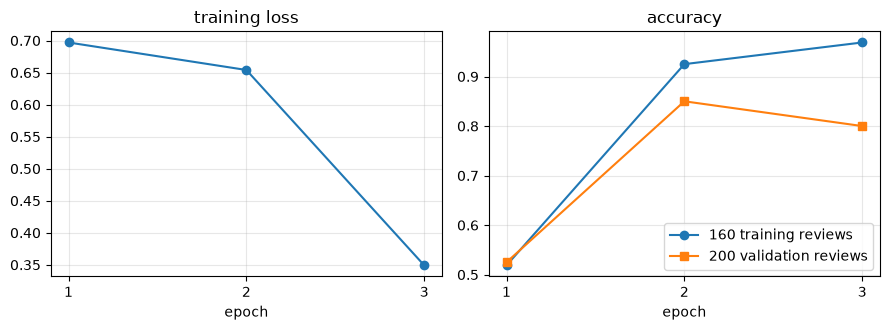

In [11]:
ep = [h[0] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(ep, [h[1] for h in history], "o-"); axes[0].set_title("training loss"); axes[0].set_xlabel("epoch")
axes[1].plot(ep, [h[2] for h in history], "o-", label=f"{len(ft_y)} training reviews")
axes[1].plot(ep, [h[3] for h in history], "s-", label=f"{len(chk_y)} validation reviews")
axes[1].set_title("accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
for a in axes: a.set_xticks(ep); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Through epoch 2, both curves rise together. In epoch 3 the training loss falls sharply and training accuracy keeps climbing, but validation accuracy drops from 0.850 to 0.800, and the gap between the two widens. With only 160 examples, the model has started to memorise them. One caution: the drop is 10 of 200 validation reviews in a single training run, so treat it as a warning sign rather than proof. But it is exactly the pattern to watch for, and it's why the fine-tuning notes choose their checkpoint on validation (Note 8.4).

### 5.2 Catastrophic forgetting

Overfitting is about the *task we're training on*. **Catastrophic forgetting** is about everything else: when a model's weights are adjusted for a new task, it can lose some of what it could do before. DistilBERT was pretrained to guess hidden words. Does our fine-tuned body still do that as well?

To find out, we hide 15% of the words in 200 validation reviews used nowhere else, and measure how well the original word-guessing head does. First on top of the pretrained body, then with the fine-tuned body swapped in. The loss is the cross-entropy of its guesses; lower is better.

In [12]:
mlm = AutoModelForMaskedLM.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE)).to(device).eval()      # the base model with its word-guessing head
held = imdb["val"][0][1000:1200]                                          # 200 validation reviews used nowhere else
enc = tok(held, truncation=True, max_length=128, padding=True, return_tensors="pt")
g = torch.Generator().manual_seed(0)
special = (enc["input_ids"] == tok.cls_token_id) | (enc["input_ids"] == tok.sep_token_id) | (enc["attention_mask"] == 0)
hide = (torch.rand(enc["input_ids"].shape, generator=g) < 0.15) & ~special   # hide 15% of the real tokens
masked_ids = enc["input_ids"].clone(); masked_ids[hide] = tok.mask_token_id
targets = enc["input_ids"].clone(); targets[~hide] = -100                 # score only the hidden tokens

def word_guessing_loss(body_state):
    m = copy.deepcopy(mlm); m.distilbert.load_state_dict(body_state)      # swap body; output projection remains tied to input embeddings
    with torch.inference_mode():
        return m(input_ids=masked_ids.to(device), attention_mask=enc["attention_mask"].to(device),
                 labels=targets.to(device)).loss.item()
print(f"hidden tokens: {int(hide.sum())}")
print(f"word-guessing loss, pretrained body:  {word_guessing_loss(start):.3f}")
print(f"word-guessing loss, fine-tuned body:  {word_guessing_loss(after):.3f}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 14194.61it/s]

hidden tokens: 3557


word-guessing loss, pretrained body:  3.381


word-guessing loss, fine-tuned body:  3.920


With the pretrained body, the word-guessing loss on the 3557 hidden words is 3.381. With the fine-tuned body, it rises to 3.920. Bodies that moved by less than 1% on average have measurably lost some of their original skill, after training on just 160 reviews. That's catastrophic forgetting in miniature. It matters when you want the adapted model to keep doing other things too, and it's one reason PEFT methods, which leave the original weights untouched, are attractive. Note 8.5 measures how much less LoRA forgets.

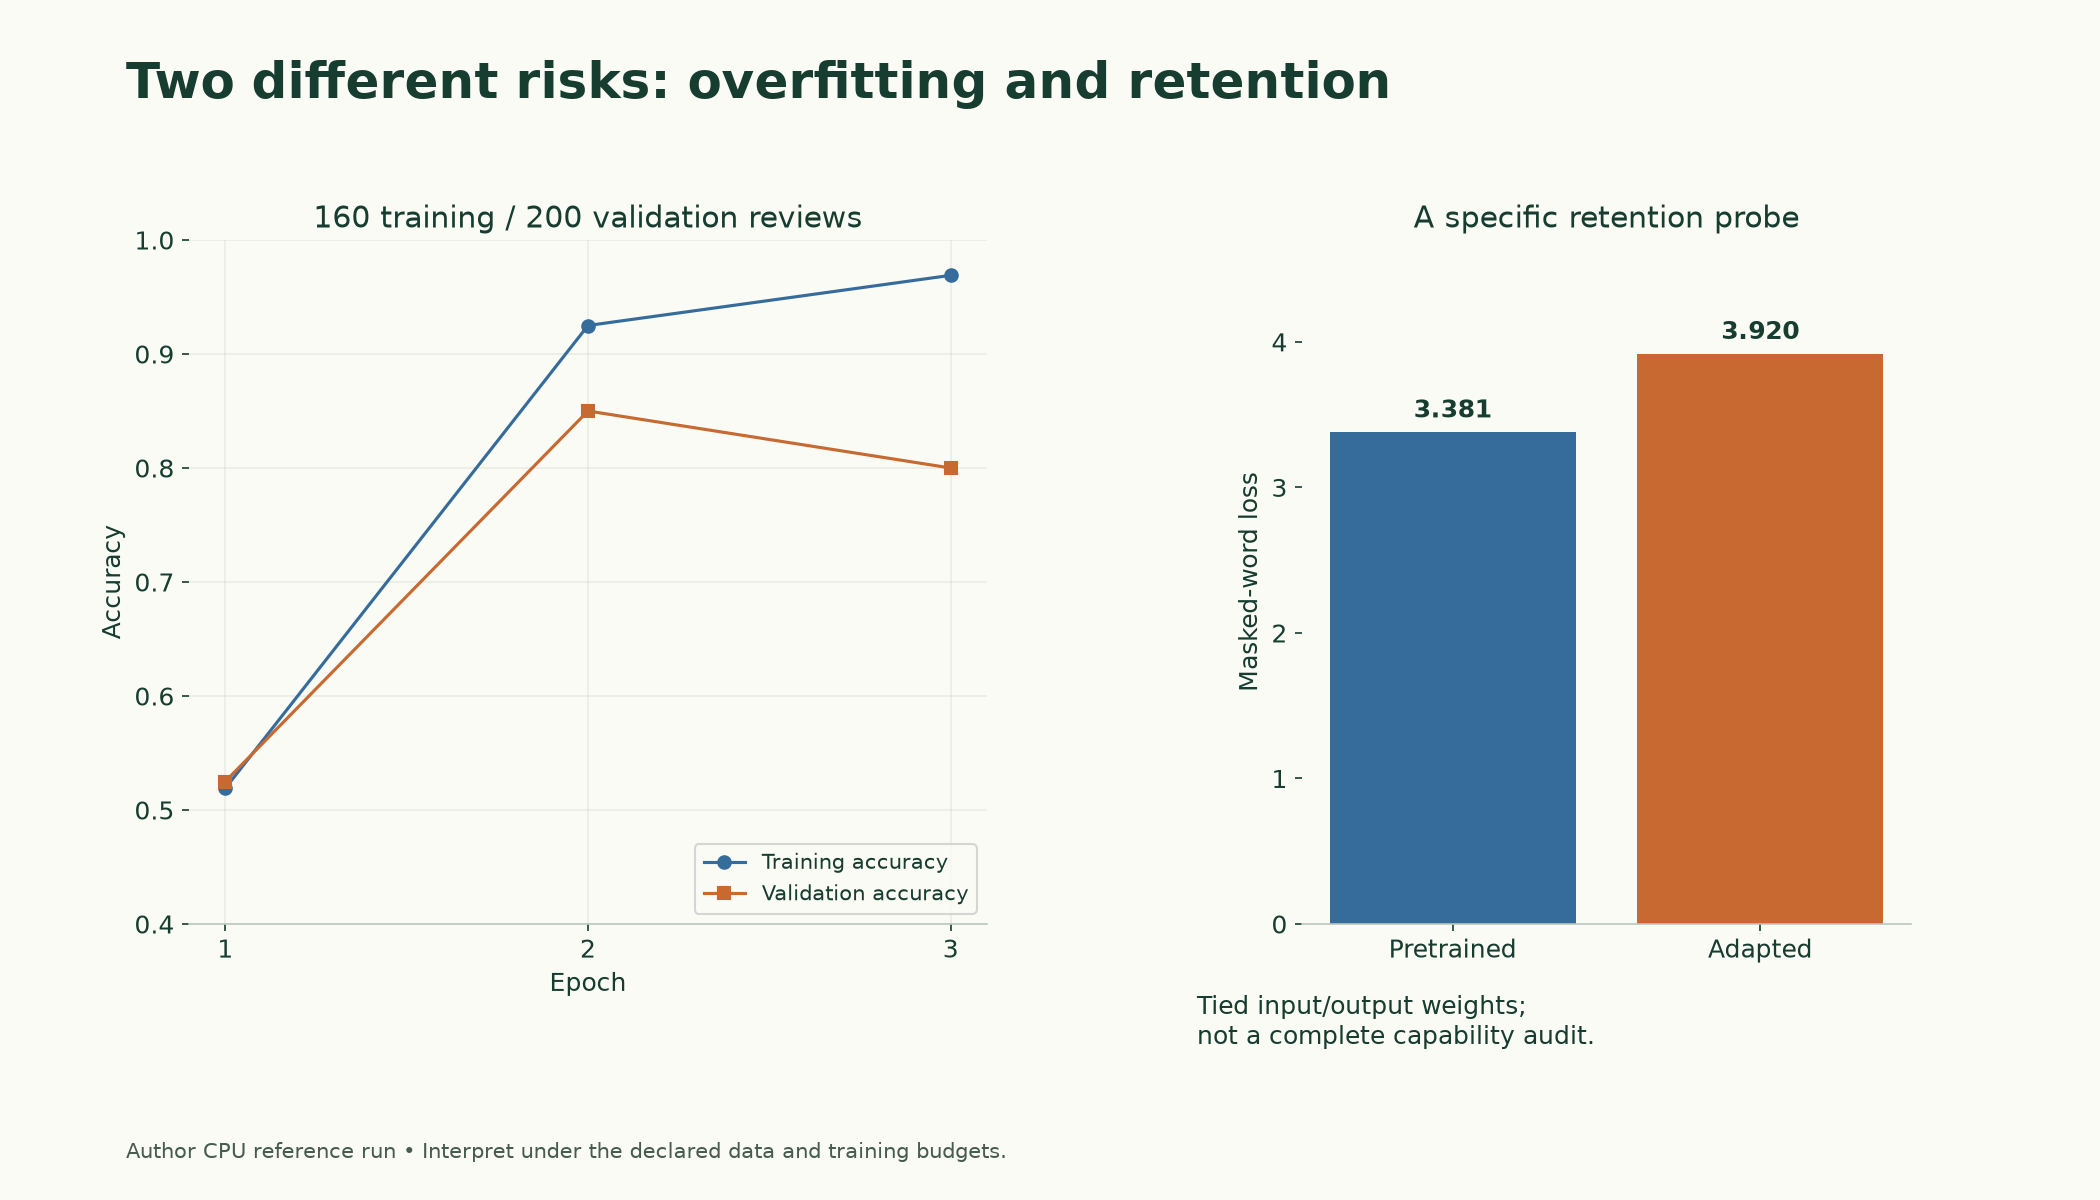

*Figure 8.1.2. Source small-run measurements illustrate an overfitting warning and degraded masked-word retention. The retention experiment uses a tied output projection and is not a complete capability audit.*

> **Key terms**
> - **Overfitting:** improving on the training examples while getting worse on new data.
> - **Catastrophic forgetting:** losing previously learned abilities when a model is trained on a new task.
> - **Masked-word (word-guessing) loss:** the cross-entropy of a masked language model's guesses for hidden words; used here as a measure of the pretrained skill.

> **Common mistake:** checking only the new task after fine-tuning. A model can score well on the task you trained it for and still have lost abilities your application relies on. If other behaviours matter, measure them before and after.

**Check yourself.**

1. A colleague says "our fine-tuned model's validation accuracy is excellent, so it can't have forgotten anything". What's wrong with that argument?

<details>
<summary>Worked answer</summary>

Validation accuracy measures only the task the model was fine-tuned for. Forgetting is about *other* abilities, such as the pretrained word-guessing skill measured in Section 5.2, which got worse even while the new task improved. To know whether anything was forgotten, you have to test those other abilities directly.

</details>

> **Interpret the evidence carefully.** This is one masked-word retention probe on 200 IMDb reviews, not a complete test of general knowledge. DistilBERT ties its vocabulary projection to its input embeddings: loading a changed body also changes those shared output weights. The other masked-word head layers remain original. This setup measures the resulting combined system; it is not a strictly fixed-decoder experiment.

## 6. Data, Compute and Quality Trade-offs: Choosing a Strategy

Putting the measurements together gives a practical way to choose. Three resources trade against each other:

- **Data.** Prompting needs no labels. Feature extraction got 0.844 from 1,000. Full fine-tuning learned the task from 160 examples but immediately began to overfit. More good labels make the heavier methods safer and stronger. Note 8.2 is about making those labels good.
- **Compute.** Prompting costs nothing to set up but runs a large model on every request. Feature extraction costs one pass to compute features and a quick fit. Fine-tuning costs real training time and memory. Full fine-tuning needs memory for every weight's gradient and optimiser state (Note 8.5 counts them), PEFT far less.
- **Quality and risk.** The heavier methods can fit a task most closely, but they risk overfitting on small data and forgetting old skills, and each fully fine-tuned task needs its own complete copy of the model.

A reasonable default path, which the rest of Module 8 follows:
1. establish **baselines**: a simple model, an off-the-shelf model and frozen features (Note 8.3);
2. try **PEFT** (Note 8.5) and **full fine-tuning** (Note 8.4) on the same data, with checkpoints chosen on validation;
3. **evaluate** everything on the same test reviews, including forgetting, and keep an adapted model only if it beats the baselines by enough to justify its costs (Note 8.7).

**Check yourself.**

1. You have 50,000 labelled support tickets, a GPU, and a requirement for a small model that answers in milliseconds. Which end of the spectrum would you start from, and why?

<details>
<summary>Worked answer</summary>

The fine-tuning end. With 50,000 labelled examples there's plenty of data to fine-tune safely, a GPU makes training practical, and a requirement for a small, fast model rules out prompting a large one. You'd still set baselines first (Note 8.3), then try PEFT and full fine-tuning of a small model, and keep the one that meets the requirement on validation and test.

</details>

## Putting It All Together

Let's reassemble the picture.

**Adaptation** turns a general pretrained model into a task-specific one, and the options form a spectrum by how much of the model they change. **Prompting** changes nothing but the input: SmolLM2-360M answered 0.84 of 100 reviews correctly with no training and no labels. **Feature extraction** freezes the model and trains a small classifier on its outputs: 0.844 on 500 reviews from 1,000 labels. **PEFT** trains a small set of added weights, and **full fine-tuning** trains them all.

Watching full fine-tuning at small scale showed both its power and its risks. From only 160 reviews, the model went from predicting "positive" for everything to 0.850 validation accuracy in two epochs, while its pretrained weights moved by less than 1% on average. But a third epoch showed **overfitting** (training accuracy 0.969, validation down to 0.800), and the fine-tuned body had suffered **degradation on this retention probe**: its word-guessing loss rose from 3.381 to 3.920.

So the choice of strategy is a trade-off between data, compute, quality and risk, made with measurements: start from the cheapest approach that could work, set baselines, and only move along the spectrum when the evidence says it's worth it.

| Approach | Weights changed | Labels used here | Measured here |
|---|---|---|---|
| Prompting (SmolLM2-360M) | none | 0 | 0.84 on 100 reviews |
| Feature extraction (frozen DistilBERT + logistic regression) | none in the pretrained model | 1,000 | 0.844 on 500 reviews |
| PEFT (LoRA) | a small added set | — | Note 8.5 |
| Full fine-tuning (small demo) | all 66,955,010 | 160 | 0.850 → 0.800 on 200 reviews; forgetting 3.381 → 3.920 |

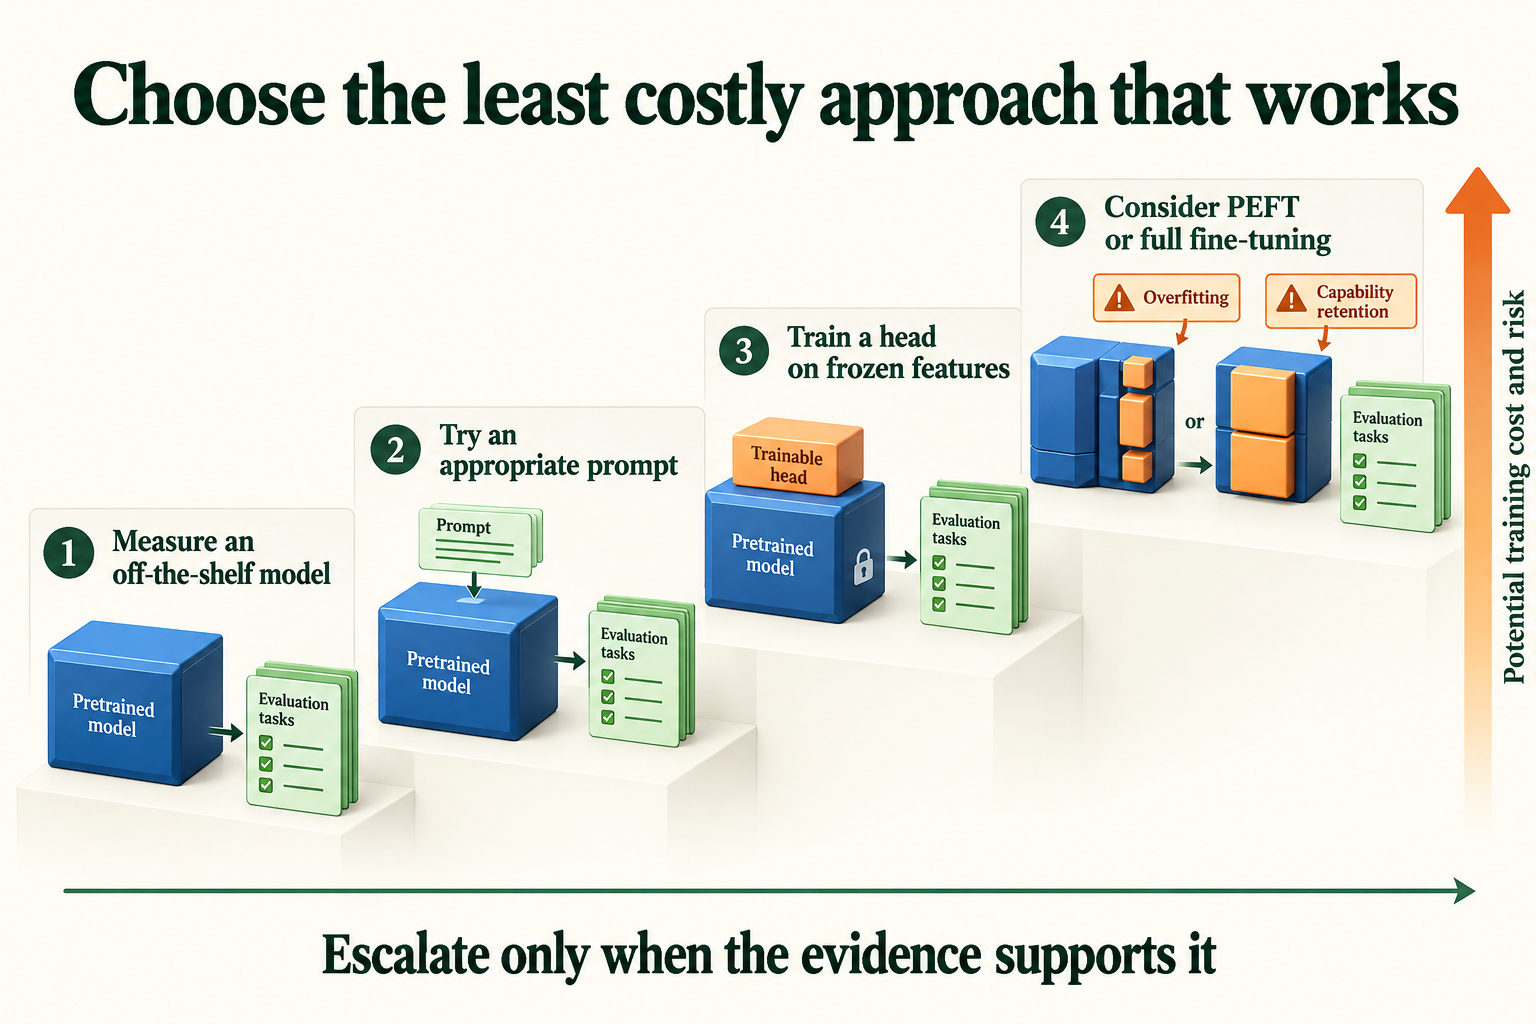

*Figure 8.1.3. Measure simpler options before adding training cost. The order is a decision aid, not a guaranteed quality ranking or a claim that every task requires an LLM prompt.*

## Summary

- **Adaptation** makes a general pretrained model better at a specific task. The spectrum runs from **prompting** (no weights change) through **feature extraction** (frozen model plus a small classifier) and **PEFT** (a few trained weights) to **full fine-tuning** (all weights).
- Prompting SmolLM2-360M-Instruct, via its **chat template**, scored 0.84 on 100 validation reviews with no labels.
- Feature extraction with frozen DistilBERT and logistic regression scored 0.844 on 500 validation reviews from 1,000 labels.
- Fine-tune only after cheaper options are measured, and not for teaching new facts, for tasks that change often, or with very few labels.
- Full fine-tuning on 160 reviews learned the task in two epochs (validation 0.850) while the pretrained weights moved by only 0.395%–0.624% on average.
- **Overfitting:** in epoch 3, training accuracy rose to 0.969 while validation fell to 0.800.
- **Retention probe:** the fine-tuned body's word-guessing loss rose from 3.381 to 3.920.
- Choosing a strategy trades data, compute, quality and risk; Module 8 follows baselines → PEFT and full fine-tuning → evaluation on the same test reviews.

## Glossary

| Term | Meaning |
|---|---|
| Adaptation | Making a general pretrained model better at a specific task. |
| Adaptation spectrum | The range of adaptation methods, ordered by how much of the model they change. |
| Prompting | Adapting a model only through its input text; no weights change. |
| Chat template | The special-marker format an instruction-tuned model expects around messages. |
| System message | An instruction placed before the conversation that sets the assistant's role. |
| Feature extraction | Using a frozen model's outputs as features for a separate small model. |
| Frozen | Not updated during training. |
| Fine-tuning | Further training of a pretrained model's own weights on task data. |
| Full fine-tuning | Fine-tuning that updates every weight. |
| PEFT | Parameter-efficient fine-tuning: training only a small set of new or selected weights. |
| LoRA | A PEFT method that adds small trainable low-rank matrices to some layers. |
| Classification head | The task-specific layer(s) on top of a pretrained body. |
| Epoch | One pass through all training examples. |
| Relative change | The size of a weight change divided by the size of the original weights. |
| Overfitting | Improving on training data while getting worse on new data. |
| Catastrophic forgetting | Losing earlier abilities when trained on a new task. |
| Masked-word loss | Cross-entropy of a masked language model's guesses for hidden words. |